# Sequential Graph

In [1]:
# Setup: install the packages (already installed in .venv, safe to skip)
%pip install -q langchain langchain_core langgraph langchain_openai

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Load the OpenRouter key and app settings from .env
import dotenv
import os
dotenv.load_dotenv(".env")

True

In [3]:
# Main model: every LLM node uses this one unless noted
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base=os.getenv("OPENROUTER_BASE_URL"),
    model_name="openai/gpt-4o-mini-2024-07-18", # Or any model on OpenRouter
    default_headers={
        "HTTP-Referer": os.getenv("APP_URL"),
        "X-Title": os.getenv("APP_NAME"),
    }
)

In [4]:
# ===== Pattern 1: Sequential flow =====
# Task: turn V5's messy vendor text into a size note a parent can use.
# Node 1 extracts the size info, node 2 writes the note: one node's output feeds the next.

from typing import TypedDict

# State: the raw listing in, the extracted size info, and the final note
class SizeNote(TypedDict):
    raw_listing: str
    size_info: str
    size_note: str

In [5]:
# Building blocks for every LLM call: prompt template | model | plain-string parser
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

In [6]:
# Node 1: pull only the size information out of the raw listing
def extract_sizes(state: SizeNote) -> SizeNote:
    raw = state["raw_listing"]
    prompt = PromptTemplate(
        template="Read this vendor listing text and write the size information only, in one short sentence: {raw}",
        input_variables=["raw"]
    )

    chain = prompt | llm | StrOutputParser()
    info = chain.invoke({"raw": raw})

    state["size_info"] = info
    return state


In [7]:
# Node 2: turn the size info into 3 bullet points that help a parent pick a size
def write_size_note(state: SizeNote) -> SizeNote:
    info = state["size_info"]
    prompt = PromptTemplate(
        template="Using these size details: {info}, write 3 bullet points as markdown that help a parent choose the right size.",
        input_variables=["info"]
    )

    chain = prompt | llm | StrOutputParser()
    note = chain.invoke({"info": info})
    state["size_note"] = note
    return state

In [8]:
from langgraph.graph import StateGraph, START, END
g = StateGraph(SizeNote)

g.add_node("extract_sizes", extract_sizes)
g.add_node("write_size_note", write_size_note)

g.add_edge(START, "extract_sizes")
g.add_edge("extract_sizes", "write_size_note")
g.add_edge("write_size_note", END)

workflow = g.compile()

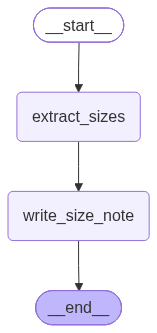

In [9]:
from IPython.display import Image, display
display(Image(workflow.get_graph().draw_mermaid_png()))

In [10]:
# Run it on one listing
initial_state = {"raw_listing": "Boys cotton dino tee. Colour: green. Tag size: 105 (CN, height in cm). Chest: 56 cm. Machine wash cold."}
final_state = workflow.invoke(initial_state)
final_state


{'raw_listing': 'Boys cotton dino tee. Colour: green. Tag size: 105 (CN, height in cm). Chest: 56 cm. Machine wash cold.',
 'size_info': 'Tag size: 105 (CN), chest: 56 cm.',
 'size_note': "- **Understanding Tag Size**: The tag size 105 (CN) typically corresponds to a child’s body measurement around 105 cm in height, so ensure your child's height aligns with this size for a comfortable fit.\n\n- **Chest Measurement Reference**: With a chest measurement of 56 cm, it’s crucial to compare this size against your child’s current chest measurement. Allow for a little extra room for movement and comfort when selecting a size.\n\n- **Check Age Guidelines**: Generally, size 105 is designed for children aged 3 to 4 years old. However, always consider your child's unique growth patterns, as they may require a different size compared to their peers."}

In [11]:
# ===== Pattern 2: Parallel flow =====
# Task: run three independent listing checks at the same time, then write one report.
# Parallel nodes return ONLY the keys they change; returning the whole state from
# three nodes in one step makes LangGraph stop with an InvalidUpdateError.

# Listing rules (illustrative)
TITLE_MAX = 60
REQUIRED_FIELDS = ["brand", "age_group", "fabric", "colour", "price"]
MIN_IMAGES = 4

In [12]:
# State: the listing, one result per check, and the final report
class ListingCheck(TypedDict):
    sku: str
    title: str
    fields: dict
    image_count: int
    title_check: dict
    fields_check: dict
    images_check: dict
    listing_report: str

In [14]:
# Check 1: title is within the character limit
def check_title(state: ListingCheck):
    n = len(state["title"])
    return {"title_check": {"ok": n <= TITLE_MAX, "detail": f"title has {n} characters (limit {TITLE_MAX})"}}

# Check 2: every required field has a value
def check_fields(state: ListingCheck):
    missing = [f for f in REQUIRED_FIELDS if not state["fields"].get(f)]
    return {"fields_check": {"ok": not missing, "detail": "all required fields present" if not missing else f"missing: {', '.join(missing)}"}}

# Check 3: enough product photos
def check_images(state: ListingCheck):
    n = state["image_count"]
    return {"images_check": {"ok": n >= MIN_IMAGES, "detail": f"{n} photos (minimum {MIN_IMAGES})"}}



# Report: runs after all checks; READY, or BLOCKED with the checks to fix
def report(state: ListingCheck):
    failed = [name for name, key in [("title", "title_check"), ("fields", "fields_check"), ("images", "images_check")]
              if not state[key]["ok"]]
    verdict = "READY for the dummy site" if not failed else f"BLOCKED, fix: {', '.join(failed)}"
    return {"listing_report": verdict}


In [15]:
graph = StateGraph(ListingCheck)

graph.add_node("check_title", check_title)
graph.add_node("check_fields", check_fields)
graph.add_node("check_images", check_images)
graph.add_node("report", report)

graph.add_edge(START, "check_title")
graph.add_edge(START, "check_fields")
graph.add_edge(START, "check_images")

graph.add_edge(["check_title", "check_fields", "check_images"], "report")
graph.add_edge("report", END)

In [16]:
workflow = graph.compile()

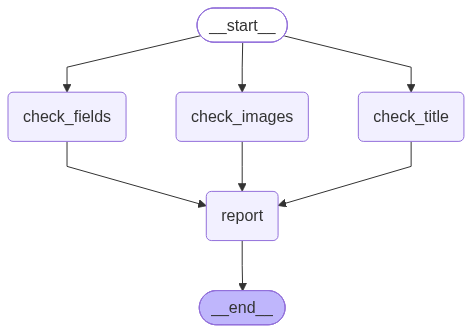

In [17]:
# Draw the graph
display(Image(workflow.get_graph().draw_mermaid_png()))


In [18]:
# A SKU that breaks all three rules
initial_state = {
    "sku": "HS-DINO-105",
    "title": "Boys Dino Print Cotton Tee Short Sleeve Round Neck Casual Wear Green",
    "fields": {"brand": "Hopscotch", "age_group": "4-5Y", "colour": "green"},
    "image_count": 3,
}
final_state = workflow.invoke(initial_state)
final_state["listing_report"]

'BLOCKED, fix: title, fields, images'

In [19]:
# A clean SKU that passes every check
clean = {
    "sku": "HS-DINO-106",
    "title": "Boys Dino Print Cotton Tee, Green",
    "fields": {"brand": "Hopscotch", "age_group": "4-5Y", "fabric": "60% cotton, 40% polyester", "colour": "green", "price": 449},
    "image_count": 5,
}
workflow.invoke(clean)["listing_report"]

'READY for the dummy site'

In [20]:
%pip install -q langchain_community pymupdf

Note: you may need to restart the kernel to use updated packages.


In [21]:
import pymupdf

# Load the PDF into LangChain documents (one per page)
# A langchain-community 'sunset' warning here is expected; the loader still works
from langchain_community.document_loaders import PyMuPDFLoader

pdf_file_path = "V5_Vendor_Profile.pdf"

loader = PyMuPDFLoader(pdf_file_path)
documents = loader.load()

C:\Users\Kartik Gupta\AppData\Local\Temp\ipykernel_50004\1169789351.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


In [22]:
documents[0].page_content

'HOPSCOTCH | VENDOR ONBOARDING PROFILE\nScenario document written for training. All figures are illustrative.\nVendor: V5 (kidswear: printed tees and sets)\nCountry: China\nStatus: onboarding in progress\nBUSINESS SUMMARY\nV5 is a newly onboarded vendor. It offered the lowest unit cost among\nthe vendors bidding for the pre-Diwali range and can ship 18,000 units\nin three weeks. Factory capacity is 40,000 units per month.\nSamples were approved for 2 of 3 style groups.\nDELIVERY RECORD\nPilot order: 4 of 4 shipments on time.\nPackaging and labelling quality on the pilot order: acceptable.\nONBOARDING CHECKLIST (6 steps)\n1. Legal and tax documents: DONE\n2. Factory audit: DONE\n3. Quality sample approval: DONE\n4. Size chart handoff to PPC (map vendor sizes to the Indian chart): SKIPPED\n5. Sample size audit against the Indian chart: SKIPPED\n6. Pilot order review: DONE\nNote from sales: "Skip steps 4 and 5 for now. We need this range live\nbefore the Diwali sale."\nSIZE LABELLING\nV5 

In [23]:
from typing import Annotated
import operator

class VendorState(TypedDict):
    vendor_profile: str
    strengths: str
    risks: str
    scores: Annotated[list[int], operator.add]
    decision: str

In [25]:
[4] + [7]

[4, 7]

In [ ]:
# Structured output: the model must return these fields, so code can rely on them
from pydantic import BaseModel, Field

class Assessment(BaseModel):
    feedback: str = Field(description="The assessment as short bullet points")
    score: int = Field(description="Score from 0 to 10 for the aspect the prompt asks about", ge=0, le=10)

llm_with_structure = llm.with_structured_output(Assessment)

# LLMs can through free text, you can prompt to give output in structured format but sometimes they hallucinate and fial
# Pydantic ensures that they give output in the required format only

In [27]:
# Try it: returns an Assessment object, not free text
llm_with_structure.invoke("The vendor delivers on time but skipped the size checks. Score the risk.")

Assessment(feedback='- Delivering on time is positive for vendor reliability.\n- Skipping size checks poses a significant risk of non-compliance with product specifications.\n- Potential for increased return rates or customer dissatisfaction due to incorrect sizes.\n- Impacts overall quality assurance processes.\n- May lead to financial implications if products are not immediately usable or require rework.', score=4)

In [28]:
# Node: strongest reasons to let V5 go live, with a score (runs alongside assess_risks)
def assess_strengths(state: VendorState):
    tem = PromptTemplate(
        template="""You advise Hopscotch's listing committee. Read this vendor profile and give the 5 strongest reasons
to allow this vendor's products to go live. Score from 0 to 10 how strong the case FOR going live is.

Vendor profile: {profile}""",
        input_variables=["profile"]
    )
    chain = tem | llm_with_structure
    result = chain.invoke({"profile": state["vendor_profile"]})
    return {"strengths": result.feedback, "scores": [result.score]}

# Node: biggest risks of letting V5 go live, with a score
def assess_risks(state: VendorState):
    tem = PromptTemplate(
        template="""You advise Hopscotch's listing committee. Read this vendor profile and give the 5 biggest risks
of letting this vendor's products go live. Score from 0 to 10 how serious those risks are.

Vendor profile: {profile}""",
        input_variables=["profile"]
    )
    chain = tem | llm_with_structure
    result = chain.invoke({"profile": state["vendor_profile"]})
    return {"risks": result.feedback, "scores": [result.score]}

# Node: waits for both assessments, then recommends ALLOW or HOLD
def decide(state: VendorState):
    tem = PromptTemplate(
        template="""Based on the strengths and risks below, should Hopscotch let V5's products go live before the
skipped onboarding checks are done? Start with ALLOW or HOLD, give 3 reasons, then name the single most important
check to run first.

Strengths: {strengths}

Risks: {risks}""",
        input_variables=["strengths", "risks"]
    )
    chain = tem | llm | StrOutputParser()
    result = chain.invoke({"strengths": state["strengths"], "risks": state["risks"]})
    return {"decision": result}

In [29]:
graph = StateGraph(VendorState)

graph.add_node("assess_strengths", assess_strengths)
graph.add_node("assess_risks", assess_risks)
graph.add_node("decide", decide)

graph.add_edge(START, "assess_strengths")
graph.add_edge(START, "assess_risks")

graph.add_edge(["assess_strengths", "assess_risks"], "decide")

graph.add_edge("decide", END)
workflow = graph.compile()

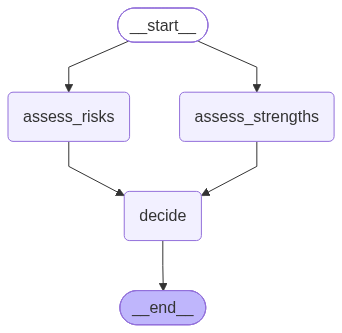

In [30]:
# Draw the graph
display(Image(workflow.get_graph().draw_mermaid_png()))


In [31]:
# Run it: both assessments run at the same time, then decide
initial_state = {"vendor_profile": documents[0].page_content}
final_state = workflow.invoke(initial_state)


In [32]:
final_state

{'vendor_profile': 'HOPSCOTCH | VENDOR ONBOARDING PROFILE\nScenario document written for training. All figures are illustrative.\nVendor: V5 (kidswear: printed tees and sets)\nCountry: China\nStatus: onboarding in progress\nBUSINESS SUMMARY\nV5 is a newly onboarded vendor. It offered the lowest unit cost among\nthe vendors bidding for the pre-Diwali range and can ship 18,000 units\nin three weeks. Factory capacity is 40,000 units per month.\nSamples were approved for 2 of 3 style groups.\nDELIVERY RECORD\nPilot order: 4 of 4 shipments on time.\nPackaging and labelling quality on the pilot order: acceptable.\nONBOARDING CHECKLIST (6 steps)\n1. Legal and tax documents: DONE\n2. Factory audit: DONE\n3. Quality sample approval: DONE\n4. Size chart handoff to PPC (map vendor sizes to the Indian chart): SKIPPED\n5. Sample size audit against the Indian chart: SKIPPED\n6. Pilot order review: DONE\nNote from sales: "Skip steps 4 and 5 for now. We need this range live\nbefore the Diwali sale."\n

In [33]:
# ===== Pattern 4: Conditional flow =====
# Task: triage a customer message. A size complaint goes to diagnosis and an
# escalation note for the PPC; everything else gets a routine reply.

# Classifier output: the model must pick one of these two categories
from typing import Literal

class SizeFlag(BaseModel):
    category: Literal["size_issue", "other"] = Field(
        description="size_issue if the customer says the size, fit or size tag is wrong, otherwise other")

llm_flag = llm.with_structured_output(SizeFlag)

In [34]:
# Try the classifier
llm_flag.invoke("The tag says 105 but the t-shirt is far too small for my son.")

SizeFlag(category='size_issue')

In [35]:
# Diagnosis output for size complaints: issue type, tone and urgency
class Diagnosis(BaseModel):
    issue_type: Literal["wrong_size_system", "fit_differs_from_chart", "size_info_missing"] = Field(
        description="The kind of size problem the customer describes")
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description="The tone of the message")
    urgency: Literal["high", "medium", "low"] = Field(description="How urgently this needs a human")

llm_diagnosis = llm.with_structured_output(Diagnosis)

In [36]:
# Try the diagnosis
llm_diagnosis.invoke("I ordered a 4-5Y dress and the tag says 110. It does not fit my daughter at all. Third time this month.").model_dump()

{'issue_type': 'wrong_size_system', 'tone': 'frustrated', 'urgency': 'high'}

In [37]:
# State: the message, its category, the diagnosis and the reply
class ReturnTriage(TypedDict):
    message: str
    category: Literal["size_issue", "other"]
    diagnosis: dict
    response: str

In [39]:
# Node: label the message size_issue or other
def classify(state: ReturnTriage):
    tem = PromptTemplate(
        template="Does this customer message say the size, fit or size tag is wrong? Message: {message}",
        input_variables=["message"]
    )
    chain = tem | llm_flag
    result = chain.invoke({"message": state["message"]})
    return {"category": result.category}

# Node: a short, warm reply for messages that are not about size
def routine_reply(state: ReturnTriage):
    tem = PromptTemplate(
        template="""Write a short, warm reply of 3 sentences to this customer message.
Sign off as Hopscotch Support. Do not use placeholders.

Message: {message}""",
        input_variables=["message"]
    )
    chain = tem | llm | StrOutputParser()
    result = chain.invoke({"message": state["message"]})
    return {"response": result}

# Node: diagnose a size complaint (issue type, tone, urgency)
def run_diagnosis(state: ReturnTriage):
    tem = PromptTemplate(
        template="Run a diagnosis on this customer message about size: {message}",
        input_variables=["message"]
    )
    chain = tem | llm_diagnosis
    result = chain.invoke({"message": state["message"]})
    return {"diagnosis": result.model_dump()}

# Node: customer reply with no automatic refund, plus a note for the PPC
def escalate(state: ReturnTriage):
    tem = PromptTemplate(
        template="""A customer reported a size problem.

Message: {message}
Issue type: {issue_type}
Tone: {tone}
Urgency: {urgency}

Write two parts.
CUSTOMER REPLY: a short reply that apologises, does not promise an automatic refund, and says a specialist will review the order.
NOTE FOR PPC: two lines that tell the post-production committee what to check.
Sign the reply as Hopscotch Support. Do not use placeholders.""",
        input_variables=["message", "issue_type", "tone", "urgency"]
    )
    chain = tem | llm | StrOutputParser()
    d = state["diagnosis"]
    result = chain.invoke({"message": state["message"], "issue_type": d["issue_type"], "tone": d["tone"], "urgency": d["urgency"]})
    return {"response": result}

# Routing function: picks the next node from the category
# (the Literal return type tells LangGraph, and the graph drawing, where it can go)
# Condition to be used in my conditional edge when I create my graph
def route_by_category(state: ReturnTriage) -> Literal["routine_reply", "run_diagnosis"]:
    if state["category"] == "other":
        return "routine_reply"
    else:
        return "run_diagnosis"

In [40]:
graph = StateGraph(ReturnTriage)

graph.add_node("classify", classify)
graph.add_node("routine_reply", routine_reply)
graph.add_node("run_diagnosis", run_diagnosis)
graph.add_node("escalate", escalate)

graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", route_by_category)
graph.add_edge("routine_reply", END)
graph.add_edge("run_diagnosis", "escalate")
graph.add_edge("escalate", END)

workflow = graph.compile()

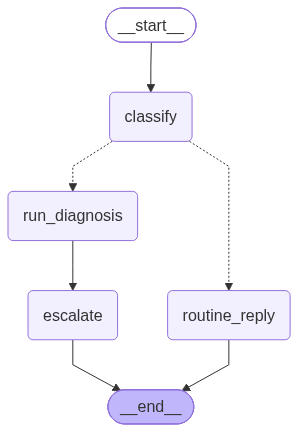

In [41]:
# Draw the graph
display(Image(workflow.get_graph().draw_mermaid_png()))


In [42]:
# A size complaint: should take the run_diagnosis -> escalate path
final_state = workflow.invoke({"message": "I ordered the green dino tee for my son. The tag says 105 but it is far too small, he is five. This is the third wrong size this month."})
final_state


{'message': 'I ordered the green dino tee for my son. The tag says 105 but it is far too small, he is five. This is the third wrong size this month.',
 'category': 'size_issue',
 'diagnosis': {'issue_type': 'wrong_size_system',
  'tone': 'frustrated',
  'urgency': 'high'},
 'response': "CUSTOMER REPLY:  \nDear Customer,  \n\nI’m sorry to hear about the sizing issue with your order. A specialist will review your order and follow up with you shortly. Thank you for your patience.  \n\nBest,  \nHopscotch Support  \n\nNOTE FOR PPC:  \n- Verify the sizing chart for the green dino tee to ensure compliance.  \n- Check the customer's order history for any patterns in size discrepancies.  "}

In [43]:
# ===== Pattern 5: Iterative flow =====
# Task: write listing copy, check it against the product facts and the Indian size chart,
# improve it if it fails, and stop when it passes or after max_iters rounds.

# Ground truth for the evaluator: a judge with nothing to check against can't verify claims
INDIAN_SIZE_CHART = """Indian size chart (illustrative, for this scenario)
2-3Y: height 92 to 98 cm
3-4Y: height 98 to 104 cm
4-5Y: height 104 to 110 cm
5-6Y: height 110 to 116 cm
6-7Y: height 116 to 122 cm"""

PRODUCT_FACTS = """Name: Dino Print Tee
Fabric: 60% cotton, 40% polyester
Colour: green
Vendor tag: 105 (CN, height in cm)
Indian size label: 4-5Y
Care: machine wash cold"""

BRIEF = "Write for the Diwali sale and make it sound premium."

In [44]:
# State: copy_history and review_log use reducers, so every round is kept
class ListingCopy(TypedDict):
    facts: str
    brief: str
    copy: str
    evaluation: Literal["approved", "needs_improvements"]
    feedback: str
    iters: int
    max_iters: int
    copy_history: Annotated[list[str], operator.add]
    review_log: Annotated[list[dict], operator.add]

In [45]:
# Reviewer output: a verdict plus feedback naming each broken rule
class CopyReview(BaseModel):
    evaluation: Literal["approved", "needs_improvements"] = Field(description="approved only if every rule is met")
    feedback: str = Field(description="If needs_improvements, list each broken rule and the exact words that break it. If approved, write none.")

reviewer = llm.with_structured_output(CopyReview)

In [46]:
# Node: write the first draft (cheaper model)
def generate_copy(state: ListingCopy):
    tem = PromptTemplate(
        template="""You write product listing copy for Hopscotch, an online kidswear marketplace.
Brief: {brief}
Product facts:
{facts}

Write the listing description in under 60 words.""",
        input_variables=["brief", "facts"]
    )
    chain = tem | llm | StrOutputParser()
    response = chain.invoke({"brief": state["brief"], "facts": state["facts"]})
    return {"copy": response, "copy_history": [response]}


# Node: judge the copy against the facts and size chart, and log the round
def evaluate_copy(state: ListingCopy):
    tem = PromptTemplate(
        template="""You are a strict listing reviewer. EVALUATE the copy, do not rewrite it.

Indian size chart:
{chart}

Product facts (the only source of truth):
{facts}

COPY TO REVIEW:
{copy}

RULES. The copy is approved only if ALL are true:
1. Every product claim (fabric, colour, care, fit) appears in the product facts.
2. If a size appears, it is the Indian size label for the product. A vendor tag number is never shown as a size.
3. It is under 60 words.
4. It contains no placeholders such as [Name].""",
        input_variables=["chart", "facts", "copy"]
    )
    chain = tem | reviewer
    result = chain.invoke({"chart": INDIAN_SIZE_CHART, "facts": state["facts"], "copy": state["copy"]})
    entry = {"round": state["iters"], "verdict": result.evaluation, "feedback": result.feedback}
    return {"evaluation": result.evaluation, "feedback": result.feedback, "review_log": [entry]}


# Node: fix only what the reviewer flagged, and count the round
def improve_copy(state: ListingCopy):
    tem = PromptTemplate(
        template="""Improve this listing copy so it fixes the reviewer's feedback.

COPY:
{copy}

FEEDBACK:
{feedback}

Product facts (the only source of truth):
{facts}

Rules: fix only what is flagged, add no new claims, stay under 60 words.
Output only the improved copy.""",
        input_variables=["copy", "feedback", "facts"]
    )
    chain = tem | llm | StrOutputParser()
    response = chain.invoke({"copy": state["copy"], "feedback": state["feedback"], "facts": state["facts"]})
    return {"copy": response, "iters": state["iters"] + 1, "copy_history": [response]}


# Stop rule: approved -> END; out of rounds -> END (a safety net, not a success);
# otherwise improve and evaluate again
def is_approved(state: ListingCopy):
    if state["evaluation"] == "approved":
        return "approved"
    elif state["iters"] >= state["max_iters"]:
        return "stop"
    else:
        return "needs_improvements"

In [47]:
# generate -> evaluate -> approved/stop: END, or needs_improvements: improve -> evaluate (loop)
graph = StateGraph(ListingCopy)

graph.add_node("generate", generate_copy)
graph.add_node("evaluate", evaluate_copy)
graph.add_node("improve", improve_copy)

graph.add_edge(START, "generate")
graph.add_edge("generate", "evaluate")
graph.add_conditional_edges("evaluate", is_approved, {"approved": END, "stop": END, "needs_improvements": "improve"})
graph.add_edge("improve", "evaluate")

workflow = graph.compile()

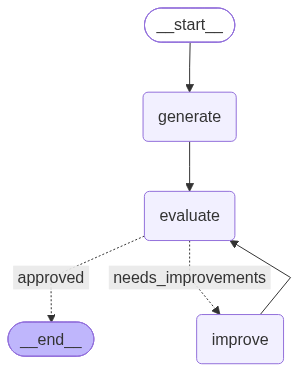

In [48]:
# Draw the graph
display(Image(workflow.get_graph().draw_mermaid_png()))


In [ ]:
# Run the loop: start at round 1, allow at most 4 rounds
initial_state = {"facts": PRODUCT_FACTS, "brief": BRIEF, "iters": 1, "max_iters": 4}
final_state = workflow.invoke(initial_state)


In [50]:
# Every round's verdict. If the last one is not approved, the loop stopped at max_iters
# and a person must review the copy before it goes live
for r in final_state["review_log"]:
    print(f"Round {r['round']}: {r['verdict']} | {r['feedback']}")


Round 1: needs_improvements | 1. The phrase 'Designed for ages 4-5Y' includes the age range instead of the Indian size label, which should be '4-5Y'. 2. The copy is 63 words long, exceeding the limit of 60 words.
Round 2: needs_improvements | 1. The phrase 'Indian size label of 4-5Y' is correct, but since the 'vendor tag: 105 (CN, height in cm)' does show a size that is not the Indian size label, it can lead to confusion. The copy should specify that the size 4-5Y is the Indian size label. 
2. The copy is 67 words long, which exceeds the limit of 60 words.
Round 3: needs_improvements | 1. Broken Rule: Every product claim - The phrase "premium" and "luxurious blend" are subjective descriptors that do not appear in the product facts. 2. Broken Rule: Size - The copy mentions the vendor tag number (105 CN) as part of the size information, which is incorrect. It should only mention the Indian size label (4-5Y). 3. Broken Rule: Word Count - The copy contains 68 words, exceeding the limit of 